# 🌡️ MOD-03 — Descarga, Procesamiento y Pivoteo de Temperatura

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martin Naranjo Escobar  

---

## 📋 Descripción del módulo

Este módulo descarga y transforma las **observaciones diarias de temperatura** del IDEAM para los municipios arroceros identificados en el MOD-02. El flujo de procesamiento es:

1. Cargar la lista de filtros territoriales generada por el MOD-02
2. Descargar registros de temperatura vía **API paginada** de datos.gov.co (recurso `sbwg-7ju4`)
3. Construir variables de calendario: Año, Mes, Día, Semestre, Periodo, mes_periodo, Jornada
4. Validar cobertura territorial y detectar outliers climáticos
5. **Agregación primaria** (nivel día): calcular media, mínima, máxima y desviación estándar diaria
6. **Agregación secundaria** (nivel mes del periodo): colapsar días dentro de cada mes semestral
7. **Pivoteo wide**: una fila por (Periodo, Depto, Municipio) con columnas `temperatura_*_m1` a `temperatura_*_m6`
8. Guardar todos los productos intermedios y finales en `data/processed/`

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD03_temperatura.ipynb          ← Este archivo
├── data/
│   ├── raw/
│   │   └── 03_raw_Temperatura.parquet   ← Descarga original sin modificar
│   └── processed/
│       ├── 14_DF_Cobertura_Territorial.xlsx  ← Entrada desde MOD-02
│       ├── 15_DF_Temperatura_Long.xlsx       ← Serie larga con variables de calendario
│       ├── 16_DF_Temperatura_Agr.xlsx        ← Agregación primaria (día)
│       ├── 17_DF_Temperatura_Agr_SD.xlsx     ← Agregación secundaria (mes semestral)
│       └── 18_DF_Temperatura_Wide.xlsx       ← Formato wide listo para MOD-05
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Descripción |
|------|-------------|
| **Entrada** | `data/processed/14_DF_Cobertura_Territorial.xlsx` — hoja `Filtros_MOD04_MOD05_MOD06` del MOD-02 |
| **Salida 1** | `data/raw/03_raw_Temperatura.parquet` — descarga original comprimida |
| **Salida 2** | `data/processed/15_DF_Temperatura_Long.xlsx` — serie larga con calendario |
| **Salida 3** | `data/processed/16_DF_Temperatura_Agr.xlsx` — métricas diarias por municipio |
| **Salida 4** | `data/processed/17_DF_Temperatura_Agr_SD.xlsx` — métricas por mes del semestre |
| **Salida 5** | `data/processed/18_DF_Temperatura_Wide.xlsx` — formato wide listo para consolidar |

---

## 🔗 Dependencias entre módulos

```
MOD-01 → MOD-02
  └─→ 14_DF_Cobertura_Territorial.xlsx (hoja Filtros_MOD04_MOD05_MOD06)
        └─→ [MOD-03]  Temperatura
              └─→ 18_DF_Temperatura_Wide.xlsx
                    └─→ MOD-05 (Consolidación Dataset Maestro)
```

---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

In [1]:
# ============================================================
# MOD-03 | Descarga, Procesamiento y Pivoteo de Temperatura
# ============================================================
!pip install openpyxl pyarrow fastparquet -q

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
import time
import warnings

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount('/content/drive')

print("✅ Entorno configurado correctamente")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 19.5 MB/s eta 0:00:00
Mounted at /content/drive
✅ Entorno configurado correctamente


---
## 📁 CELDA 2 — Definición de rutas del proyecto

> **Instrucción:** Verifica que `RUTA_BASE` coincida con la carpeta en tu Google Drive.  
> Ajusta `FECHA_INI` / `FECHA_FIN` si el rango del proyecto cambia.

In [13]:
# ============================================================
# CONFIGURACIÓN DE RUTAS Y PARÁMETROS — Módulo MOD-03
# ============================================================

# ⚠️ Ajusta esta ruta si tu carpeta en Drive tiene otro nombre
RUTA_BASE      = "/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II"

# Subcarpetas del proyecto
RUTA_RAW       = os.path.join(RUTA_BASE, "data", "raw")
RUTA_PROCESSED = os.path.join(RUTA_BASE, "data", "processed")
RUTA_BACKUP    = os.path.join(RUTA_BASE, "backup")

for ruta in [RUTA_RAW, RUTA_PROCESSED, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# ── Archivos de ENTRADA (generados por MOD-02) ──────────────
ENTRADA_COBERTURA  = os.path.join(RUTA_PROCESSED, "14_DF_Cobertura_Territorial.xlsx")

# ── Archivos de SALIDA de este módulo ───────────────────────
ARCHIVO_RAW_PARQUET  = os.path.join(RUTA_RAW,       "03_raw_Temperatura.parquet")
ARCHIVO_LONG_PARQUET = os.path.join(RUTA_PROCESSED,  "15_DF_Temperatura_Long.parquet")  # Parquet: soporta >1M filas
ARCHIVO_LONG         = os.path.join(RUTA_PROCESSED,  "15_DF_Temperatura_Long.xlsx")     # Excel: solo muestra (primeras 50K)
ARCHIVO_AGR_PARQUET  = os.path.join(RUTA_PROCESSED,  "16_DF_Temperatura_Agr.parquet")   # Parquet: puede superar 1M filas
ARCHIVO_AGR          = os.path.join(RUTA_PROCESSED,  "16_DF_Temperatura_Agr.xlsx")      # Excel: solo muestra (primeras 50K)
ARCHIVO_AGR_SD       = os.path.join(RUTA_PROCESSED,  "17_DF_Temperatura_Agr_SD.xlsx")
ARCHIVO_WIDE         = os.path.join(RUTA_PROCESSED,  "18_DF_Temperatura_Wide.xlsx")

# ── Parámetros de descarga ───────────────────────────────────
URL_TEMPERATURA = "https://www.datos.gov.co/resource/sbwg-7ju4.json"
FECHA_INI       = "2020-01-01"   # ⚠️ Ajustar si el rango cambia
FECHA_FIN       = "2024-12-31"   # ⚠️ Ajustar si el rango cambia
LIMIT_PAGINA    = 10000          # Registros por página de la API
MAX_PAGINAS     = 500            # Límite de seguridad anti-bucle infinito
TIMEOUT_API     = 300            # Segundos de timeout por petición

# ── Parámetros de control de calidad ────────────────────────
TEMP_MIN_VALIDA =  0.0   # °C — umbral inferior físicamente plausible
TEMP_MAX_VALIDA = 45.0   # °C — umbral superior físicamente plausible

print("📂 Rutas configuradas:")
print(f"   Raw      → {RUTA_RAW}")
print(f"   Processed→ {RUTA_PROCESSED}")
print(f"\n📅 Rango temporal: {FECHA_INI}  →  {FECHA_FIN}")
print()
existe = '✅' if os.path.exists(ENTRADA_COBERTURA) else '❌ NO ENCONTRADO — Ejecuta primero MOD-02'
print(f"📥 Entrada: {existe}  14_DF_Cobertura_Territorial.xlsx")
print()
print("📤 Salidas que generará este módulo:")
for f in ["03_raw_Temperatura.parquet","15_DF_Temperatura_Long.parquet",
          "16_DF_Temperatura_Agr.parquet","17_DF_Temperatura_Agr_SD.xlsx",
          "18_DF_Temperatura_Wide.xlsx"]:
    print(f"   📄 {f}")

📂 Rutas configuradas:
   Raw      → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw
   Processed→ /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed

📅 Rango temporal: 2020-01-01  →  2024-12-31

📥 Entrada: ✅  14_DF_Cobertura_Territorial.xlsx

📤 Salidas que generará este módulo:
   📄 03_raw_Temperatura.parquet
   📄 15_DF_Temperatura_Long.parquet
   📄 16_DF_Temperatura_Agr.parquet
   📄 17_DF_Temperatura_Agr_SD.xlsx
   📄 18_DF_Temperatura_Wide.xlsx


---
## 🔧 CELDA 3 — Funciones utilitarias y de descarga

In [3]:
# ============================================================
# FUNCIONES UTILITARIAS Y DE DESCARGA — Módulo MOD-03
# ============================================================

# ── Normalización de texto ───────────────────────────────────
def normalizar_texto(serie):
    """Estandariza texto: string → strip → mayúsculas."""
    return serie.astype(str).str.strip().str.upper()


def crear_clave_territorial(df, col_depto, col_mun):
    """Clave compuesta 'DEPTO|MUNICIPIO' para cruces entre DataFrames."""
    return normalizar_texto(df[col_depto]) + "|" + normalizar_texto(df[col_mun])


# ── Construcción de cláusula WHERE para la API SoQL ─────────
def _safe_literal(s: str) -> str:
    """Mayúsculas y escape de comillas simples para cláusula SoQL $where."""
    return str(s).upper().replace("'", "''") if s else ""


def build_where(depto: str, mpio: str, fecha_ini: str, fecha_fin: str) -> str:
    """Genera la cláusula $where para filtrar por territorio y rango de fechas."""
    d, m = _safe_literal(depto), _safe_literal(mpio)
    return (
        f"(upper(departamento)='{d}' AND upper(municipio)='{m}') "
        f"AND fechaobservacion between '{fecha_ini}T00:00:00' and '{fecha_fin}T23:59:59'"
    )


# ── Descarga paginada genérica ───────────────────────────────
def descargar_paginado(url, where, limit=10000, max_pages=500,
                       timeout=300, pausa=0.3):
    """
    Descarga todos los registros que satisfacen 'where' desde la API SoQL.
    Maneja paginación automática; se detiene cuando llega una página vacía
    o con menos registros que 'limit'.
    Parámetros:
        pausa : segundos de espera entre páginas (evita saturar la API)
    """
    offset, dfs = 0, []
    for page in range(1, max_pages + 1):
        params = {"$where": where, "$limit": limit, "$offset": offset}
        try:
            r = requests.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            data = r.json()
        except Exception as e:
            print(f"    ⚠️  Error en página {page}: {e}. Reintentando...")
            time.sleep(5)
            r = requests.get(url, params=params, timeout=timeout)
            r.raise_for_status()
            data = r.json()

        print(f"    Pág {page:3d} | offset={offset:7,} | registros={len(data):,}")
        if not data:
            break
        dfs.append(pd.DataFrame(data))
        offset += limit
        if len(data) < limit:
            break
        time.sleep(pausa)

    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


# ── Reporte rápido de DataFrame ──────────────────────────────
def reporte_df(df, nombre="DataFrame"):
    print(f"\n{'='*58}")
    print(f"  📊 {nombre}")
    print(f"{'='*58}")
    print(f"  Filas    : {df.shape[0]:,}")
    print(f"  Columnas : {df.shape[1]}")
    nulos = df.isna().sum()
    nulos_cols = nulos[nulos > 0]
    if nulos_cols.empty:
        print("  Nulos    : ✅ Sin valores nulos")
    else:
        print(f"  Nulos    : ⚠️  {len(nulos_cols)} cols con nulos")
        for c, n in nulos_cols.items():
            print(f"             - {c}: {n:,} ({n/len(df)*100:.1f}%)")
    print(f"{'='*58}\n")


# ── Guardar Excel ────────────────────────────────────────────
def guardar_excel(df_o_dict, ruta, nombre_log=""):
    """Guarda DataFrame o dict {hoja: df} como Excel."""
    etiqueta = nombre_log or os.path.basename(ruta)
    if isinstance(df_o_dict, dict):
        with pd.ExcelWriter(ruta, engine="openpyxl") as w:
            for hoja, df in df_o_dict.items():
                df.to_excel(w, sheet_name=hoja, index=False)
        total = sum(d.shape[0] for d in df_o_dict.values())
        print(f"✅ {etiqueta} → {ruta}")
        print(f"   Hojas: {list(df_o_dict.keys())} | Total filas: {total:,}\n")
    else:
        df_o_dict.to_excel(ruta, index=False, engine="openpyxl")
        print(f"✅ {etiqueta} → {ruta}")
        print(f"   Shape: {df_o_dict.shape[0]:,} × {df_o_dict.shape[1]}\n")


print("✅ Funciones utilitarias cargadas")

✅ Funciones utilitarias cargadas


---
## 📥 CELDA 4 — Cargar lista de filtros territoriales desde MOD-02

> Requiere que **MOD-02** haya sido ejecutado previamente.

In [4]:
# ============================================================
# CARGAR FILTROS TERRITORIALES — Entrada desde MOD-02
# ============================================================

if not os.path.exists(ENTRADA_COBERTURA):
    raise FileNotFoundError(
        f"❌ Archivo no encontrado: {ENTRADA_COBERTURA}\n"
        "   Ejecuta primero MOD02_estaciones_climaticas.ipynb"
    )

df_filtros = pd.read_excel(
    ENTRADA_COBERTURA,
    sheet_name="Filtros_MOD04_MOD05_MOD06",
    engine="openpyxl"
)

# Normalizar texto
df_filtros["Departamento"] = normalizar_texto(df_filtros["Departamento"])
df_filtros["Municipio"]    = normalizar_texto(df_filtros["Municipio"])

# Lista de tuplas para el loop de descarga
filtros = list(
    df_filtros[["Departamento", "Municipio"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)

print(f"✅ Filtros territoriales cargados desde MOD-02")
print(f"   Total pares (depto, municipio): {len(filtros)}")
print()
for i, (d, m) in enumerate(filtros, 1):
    est = df_filtros[
        (df_filtros["Departamento"]==d) & (df_filtros["Municipio"]==m)
    ]["tiene_estacion"].values[0] if "tiene_estacion" in df_filtros.columns else "?"
    print(f"  {i:2d}. {d:20s} — {m:25s}  [estación: {est}]")

✅ Filtros territoriales cargados desde MOD-02
   Total pares (depto, municipio): 97

   1. ANTIOQUIA            — PUERTO BERRÍO              [estación: SÍ]
   2. ARAUCA               — FORTUL                     [estación: NO]
   3. ATLÁNTICO            — REPELÓN                    [estación: NO]
   4. BOLÍVAR              — ACHÍ                       [estación: NO]
   5. BOLÍVAR              — ARENAL                     [estación: NO]
   6. BOLÍVAR              — CÓRDOBA                    [estación: NO]
   7. BOLÍVAR              — MAHATES                    [estación: NO]
   8. BOLÍVAR              — MARÍA LA BAJA              [estación: NO]
   9. BOLÍVAR              — MORALES                    [estación: NO]
  10. BOLÍVAR              — REGIDOR                    [estación: NO]
  11. CASANARE             — AGUAZUL                    [estación: SÍ]
  12. CASANARE             — NUNCHÍA                    [estación: SÍ]
  13. CASANARE             — PAZ DE ARIPORO             [estaci

---
## 🌐 CELDA 5 — Descarga paginada de temperatura desde datos.gov.co

> **Nota:** Esta celda puede tardar varios minutos dependiendo del número de municipios  
> y del volumen de observaciones disponibles. No interrumpir durante la ejecución.

In [5]:
# ============================================================
# DESCARGA PAGINADA — Temperatura IDEAM (recurso sbwg-7ju4)
# ============================================================

print(f"🌐 Iniciando descarga de temperatura")
print(f"   Fuente  : {URL_TEMPERATURA}")
print(f"   Rango   : {FECHA_INI}  →  {FECHA_FIN}")
print(f"   Municipios a descargar: {len(filtros)}")
print("=" * 58)

dfs_all      = []
sin_registros = []
t_inicio      = time.time()

for i, (depto, mpio) in enumerate(filtros, start=1):
    print(f"\n[{i}/{len(filtros)}] {depto} — {mpio}")
    where_i = build_where(depto, mpio, FECHA_INI, FECHA_FIN)
    df_i    = descargar_paginado(
        URL_TEMPERATURA, where_i,
        limit=LIMIT_PAGINA, max_pages=MAX_PAGINAS, timeout=TIMEOUT_API
    )

    if df_i.empty:
        print(f"    ⚠️  Sin registros para {depto} — {mpio}")
        sin_registros.append((depto, mpio))
        continue

    # Trazabilidad del filtro aplicado
    df_i["depto_filtro"] = depto
    df_i["mpio_filtro"]  = mpio
    dfs_all.append(df_i)
    print(f"    ✅ {len(df_i):,} registros descargados")

# ── Consolidar ──────────────────────────────────────────────
df_temperatura_raw = (
    pd.concat(dfs_all, ignore_index=True) if dfs_all else pd.DataFrame()
)

t_total = time.time() - t_inicio
print(f"\n{'='*58}")
print(f"  ✅ Descarga completada en {t_total/60:.1f} min")
print(f"  Total registros brutos : {len(df_temperatura_raw):,}")
print(f"  Municipios con datos   : {len(filtros)-len(sin_registros)}/{len(filtros)}")
if sin_registros:
    print(f"  Sin registros: {sin_registros}")
print(f"{'='*58}")

🌐 Iniciando descarga de temperatura
   Fuente  : https://www.datos.gov.co/resource/sbwg-7ju4.json
   Rango   : 2020-01-01  →  2024-12-31
   Municipios a descargar: 97

[1/97] ANTIOQUIA — PUERTO BERRÍO
    Pág   1 | offset=      0 | registros=1
    ✅ 1 registros descargados

[2/97] ARAUCA — FORTUL
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para ARAUCA — FORTUL

[3/97] ATLÁNTICO — REPELÓN
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para ATLÁNTICO — REPELÓN

[4/97] BOLÍVAR — ACHÍ
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para BOLÍVAR — ACHÍ

[5/97] BOLÍVAR — ARENAL
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para BOLÍVAR — ARENAL

[6/97] BOLÍVAR — CÓRDOBA
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para BOLÍVAR — CÓRDOBA

[7/97] BOLÍVAR — MAHATES
    Pág   1 | offset=      0 | registros=0
    ⚠️  Sin registros para BOLÍVAR — MAHATES

[8/97] BOLÍVAR — MARÍA LA BAJA
    Pág   1 | offs

---
## 💾 CELDA 6 — Guardar descarga original en `data/raw/`

Se guarda en formato **Parquet** para preservar tipos de datos y reducir el tamaño del archivo.

In [6]:
# ============================================================
# GUARDAR DESCARGA RAW — data/raw/03_raw_Temperatura.parquet
# ============================================================

if not df_temperatura_raw.empty:
    df_temperatura_raw.to_parquet(ARCHIVO_RAW_PARQUET, index=False)
    size_mb = os.path.getsize(ARCHIVO_RAW_PARQUET) / 1_048_576
    print(f"✅ Guardado: 03_raw_Temperatura.parquet")
    print(f"   Ruta  : {ARCHIVO_RAW_PARQUET}")
    print(f"   Shape : {df_temperatura_raw.shape[0]:,} × {df_temperatura_raw.shape[1]}")
    print(f"   Tamaño: {size_mb:.2f} MB")
    print()
    print(f"📋 Columnas disponibles de la API:")
    print(df_temperatura_raw.columns.tolist())
else:
    print("❌ No hay datos descargados. Revisa los filtros territoriales y la conectividad.")

✅ Guardado: 03_raw_Temperatura.parquet
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/03_raw_Temperatura.parquet
   Shape : 2,065,387 × 14
   Tamaño: 18.03 MB

📋 Columnas disponibles de la API:
['codigoestacion', 'codigosensor', 'fechaobservacion', 'valorobservado', 'nombreestacion', 'departamento', 'municipio', 'zonahidrografica', 'latitud', 'longitud', 'descripcionsensor', 'unidadmedida', 'depto_filtro', 'mpio_filtro']


---
## 🧹 CELDA 7 — Limpieza de tipos de datos

In [7]:
# ============================================================
# LIMPIEZA DE TIPOS DE DATOS
# ============================================================

df_temp = df_temperatura_raw.copy()

# ── 1. Fecha de observación → datetime ──────────────────────
print("1️⃣  Convirtiendo fechaobservacion a datetime...")
df_temp["fechaobservacion"] = pd.to_datetime(
    df_temp["fechaobservacion"], errors="coerce"
)
n_fecha_nula = df_temp["fechaobservacion"].isna().sum()
if n_fecha_nula > 0:
    print(f"   ⚠️  {n_fecha_nula:,} registros con fecha inválida (se eliminarán)")
    df_temp = df_temp.dropna(subset=["fechaobservacion"]).copy()

# ── 2. Valor observado → numérico ───────────────────────────
print("2️⃣  Convirtiendo valorobservado a float...")
df_temp["valorobservado"] = pd.to_numeric(
    df_temp["valorobservado"], errors="coerce"
)

# ── 3. Coordenadas → numérico ────────────────────────────────
print("3️⃣  Convirtiendo coordenadas a float...")
for col in ["latitud", "longitud", "altitud"]:
    if col in df_temp.columns:
        df_temp[col] = pd.to_numeric(df_temp[col], errors="coerce")

# ── 4. Normalizar texto de departamento y municipio ─────────
print("4️⃣  Normalizando departamento y municipio...")
for col in ["departamento", "municipio"]:
    if col in df_temp.columns:
        df_temp[col] = normalizar_texto(df_temp[col])

# ── 5. Resetear índice ───────────────────────────────────────
df_temp = df_temp.reset_index(drop=True)

print()
reporte_df(df_temp, "df_temp — Temperatura con tipos corregidos")
display(df_temp.head(3))

1️⃣  Convirtiendo fechaobservacion a datetime...
2️⃣  Convirtiendo valorobservado a float...
3️⃣  Convirtiendo coordenadas a float...
4️⃣  Normalizando departamento y municipio...


  📊 df_temp — Temperatura con tipos corregidos
  Filas    : 2,065,387
  Columnas : 14
  Nulos    : ✅ Sin valores nulos



,codigoestacion,codigosensor,fechaobservacion,valorobservado,nombreestacion,departamento,municipio,zonahidrografica,latitud,longitud,descripcionsensor,unidadmedida,depto_filtro,mpio_filtro
0,0023097030,0068,2022-08-25 14:00:00,24.4,PTO BERRIO TX GPRS,ANTIOQUIA,PUERTO BERRÍO,MEDIO MAGDALENA,6.485000,-74.401000,Temp Aire 2 m,°C,ANTIOQUIA,PUERTO BERRÍO
1,0036015020,0068,2020-01-21 07:00:00,25.6,EL DIAMANTE - AUT,CASANARE,PAZ DE ARIPORO,META,5.816194,-71.419833,Temp Aire 2 m,°C,CASANARE,PAZ DE ARIPORO
2,0036015020,0068,2020-01-21 18:00:00,28.1,EL DIAMANTE - AUT,CASANARE,PAZ DE ARIPORO,META,5.816194,-71.419833,Temp Aire 2 m,°C,CASANARE,PAZ DE ARIPORO


---
## 📅 CELDA 8 — Construcción de variables de calendario

Las variables de calendario son la clave para la agregación semestral del proyecto:  
- **Semestre**: A (ene-jun) o B (jul-dic)  
- **Periodo**: combinación Año + Semestre (ej. `2022A`)  
- **mes_periodo**: posición del mes dentro del semestre (1 a 6)  
- **Jornada**: D (diurna: 6h-17h) o N (nocturna)

In [8]:
# ============================================================
# VARIABLES DE CALENDARIO
# ============================================================

print("🗓️  Construyendo variables de calendario...")

# ── Componentes básicos ──────────────────────────────────────
df_temp["Año"]  = df_temp["fechaobservacion"].dt.year
df_temp["Mes"]  = df_temp["fechaobservacion"].dt.month
df_temp["Dia"]  = df_temp["fechaobservacion"].dt.day
df_temp["Hora"] = df_temp["fechaobservacion"].dt.hour

# ── Semestre: A (ene-jun=1-6) | B (jul-dic=7-12) ────────────
df_temp["Semestre"] = df_temp["Mes"].map(
    lambda x: "A" if 1 <= x <= 6 else ("B" if 7 <= x <= 12 else None)
)

# ── Periodo: 'AAAA' + 'S'  (ej. '2022A', '2023B') ───────────
df_temp["Periodo"] = (
    df_temp["Año"].astype("Int64").astype(str)
    + df_temp["Semestre"].astype(str)
)

# ── mes_periodo: posición dentro del semestre (1 a 6) ────────
# Ene=1,Feb=2,...,Jun=6 → mes_periodo 1..6
# Jul=1,Ago=2,...,Dic=6 → mes_periodo 1..6
df_temp["mes_periodo"] = ((df_temp["Mes"] - 1) % 6) + 1

# ── Jornada: D (6h-17h diurna) | N (nocturna) ───────────────
df_temp["Jornada"] = df_temp["Hora"].map(
    lambda h: "D" if 6 <= h <= 17 else "N"
)

# ── Verificación ────────────────────────────────────────────
print("\n📅 Vista rápida de variables de calendario:")
display(
    df_temp[
        ["fechaobservacion", "Año", "Mes", "Dia", "Hora",
         "Semestre", "Periodo", "mes_periodo", "Jornada"]
    ].head(8)
)

print("\n📊 Distribución por Periodo:")
print(df_temp["Periodo"].value_counts().sort_index().to_string())

print("\n📊 Distribución por Jornada:")
print(df_temp["Jornada"].value_counts().to_string())

🗓️  Construyendo variables de calendario...

📅 Vista rápida de variables de calendario:


,fechaobservacion,Año,Mes,Dia,Hora,Semestre,Periodo,mes_periodo,Jornada
0,2022-08-25 14:00:00,2022,8,25,14,B,2022B,2,D
1,2020-01-21 07:00:00,2020,1,21,7,A,2020A,1,D
2,2020-01-21 18:00:00,2020,1,21,18,A,2020A,1,N
3,2020-01-21 05:00:00,2020,1,21,5,A,2020A,1,N
4,2020-01-21 08:00:00,2020,1,21,8,A,2020A,1,D
5,2020-01-21 20:00:00,2020,1,21,20,A,2020A,1,N
6,2020-01-21 22:00:00,2020,1,21,22,A,2020A,1,N
7,2020-01-21 02:00:00,2020,1,21,2,A,2020A,1,N



📊 Distribución por Periodo:
Periodo
2020A    289299
2020B    232140
2021A    136889
2021B    221480
2022A    146428
2022B    142798
2023A    185140
2023B    195013
2024A    221865
2024B    294335

📊 Distribución por Jornada:
Jornada
D    1066514
N     998873


---
## 🔍 CELDA 9 — Validación de cobertura territorial

Verifica que los municipios solicitados en los filtros efectivamente aparecen  
en los datos descargados.

In [9]:
# ============================================================
# VALIDACIÓN DE COBERTURA TERRITORIAL
# ============================================================

# Claves únicas en los datos descargados
df_temp["key"] = crear_clave_territorial(df_temp, "departamento", "municipio")

keys_descargadas = set(df_temp["key"].dropna())

# Evaluar cada filtro solicitado
df_filtros["key"] = crear_clave_territorial(df_filtros, "Departamento", "Municipio")
df_filtros["en_temperatura"] = df_filtros["key"].isin(keys_descargadas)

n_total      = len(df_filtros)
n_encontrado = df_filtros["en_temperatura"].sum()
n_faltante   = n_total - n_encontrado

print("=" * 55)
print("  🗺️  COBERTURA TERRITORIAL — Temperatura")
print("=" * 55)
print(f"  Municipios solicitados    : {n_total}")
print(f"  Con datos descargados     : {n_encontrado}  ({n_encontrado/n_total*100:.1f}%)")
print(f"  Sin datos (API vacía)     : {n_faltante}  ({n_faltante/n_total*100:.1f}%)")
print("=" * 55)

if n_faltante > 0:
    faltantes = df_filtros[~df_filtros["en_temperatura"]][["Departamento","Municipio"]]
    print("\n⚠️  Municipios sin datos de temperatura:")
    display(faltantes.reset_index(drop=True))
    print("   → Se imputarán en MOD-06 con mediana del departamento o global.")

print("\n📊 Registros por municipio:")
display(
    df_temp.groupby(["departamento","municipio"])
           .size()
           .reset_index(name="n_registros")
           .sort_values("n_registros", ascending=False)
)

  🗺️  COBERTURA TERRITORIAL — Temperatura
  Municipios solicitados    : 97
  Con datos descargados     : 36  (37.1%)
  Sin datos (API vacía)     : 61  (62.9%)

⚠️  Municipios sin datos de temperatura:


,Departamento,Municipio
0,ARAUCA,FORTUL
1,ATLÁNTICO,REPELÓN
2,BOLÍVAR,ACHÍ
3,BOLÍVAR,ARENAL
4,BOLÍVAR,CÓRDOBA
...,...,...
56,TOLIMA,PIEDRAS
57,TOLIMA,PRADO
58,TOLIMA,PURIFICACIÓN
59,TOLIMA,SAN LUIS


   → Se imputarán en MOD-06 con mediana del departamento o global.

📊 Registros por municipio:


,departamento,municipio,n_registros
8,CESAR,VALLEDUPAR,462553
32,TOLIMA,IBAGUÉ,327519
28,TOLIMA,ATACO,288596
15,HUILA,TELLO,241464
35,VALLE DEL CAUCA,JAMUNDÍ,194173
9,CÓRDOBA,MONTERÍA,184458
21,META,PUERTO LÓPEZ,40353
22,META,VILLAVICENCIO,31460
19,MAGDALENA,ZONA BANANERA,21574
1,CASANARE,PAZ DE ARIPORO,20722


---
## 🚨 CELDA 10 — Control de calidad: detección de outliers climáticos

Se aplican dos filtros de calidad sobre `valorobservado`:  
1. **Rango físico plausible**: elimina temperaturas fuera de `[TEMP_MIN_VALIDA, TEMP_MAX_VALIDA]`  
2. **Rango estadístico (IQR)**: detecta (pero no elimina) valores extremos por municipio

In [10]:
# ============================================================
# CONTROL DE CALIDAD — Outliers en valorobservado
# ============================================================

n_antes = len(df_temp)

# ── 1. Eliminar valores nulos en valorobservado ──────────────
n_nulos = df_temp["valorobservado"].isna().sum()
df_temp = df_temp.dropna(subset=["valorobservado"]).copy()
print(f"1️⃣  Valores nulos eliminados en valorobservado: {n_nulos:,}")

# ── 2. Filtro de rango físico plausible ──────────────────────
mascara_fisica = (
    df_temp["valorobservado"].between(TEMP_MIN_VALIDA, TEMP_MAX_VALIDA)
)
n_fuera_rango = (~mascara_fisica).sum()
df_temp = df_temp[mascara_fisica].copy()
print(f"2️⃣  Registros fuera de rango [{TEMP_MIN_VALIDA}°C, {TEMP_MAX_VALIDA}°C]: {n_fuera_rango:,}")

# ── 3. Detección estadística de outliers por municipio (IQR) ─
print("3️⃣  Detectando outliers estadísticos por municipio (IQR × 1.5)...")

def flag_outlier_iqr(grupo):
    q1, q3 = grupo["valorobservado"].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return ~grupo["valorobservado"].between(lim_inf, lim_sup)

df_temp["outlier_iqr"] = (
    df_temp.groupby(["departamento", "municipio"], group_keys=False)
           .apply(flag_outlier_iqr)
)

n_outlier = df_temp["outlier_iqr"].sum()
pct_outlier = n_outlier / len(df_temp) * 100

print(f"   Outliers IQR detectados: {n_outlier:,} ({pct_outlier:.2f}% del total)")
print(f"   ➡️  Se mantienen en el dataset con la bandera 'outlier_iqr' para trazabilidad.")
print(f"      La imputación o exclusión se realizará en MOD-06.")

# ── Resumen final ────────────────────────────────────────────
n_despues = len(df_temp)
print(f"\n{'─'*50}")
print(f"  Registros antes del QC : {n_antes:,}")
print(f"  Registros después del QC: {n_despues:,}")
print(f"  Eliminados (nulos + rango): {n_antes - n_despues:,}")

# Estadísticas de temperatura después del QC
print("\n📊 Estadísticas de valorobservado (post-QC):")
display(df_temp["valorobservado"].describe().round(3).to_frame())

1️⃣  Valores nulos eliminados en valorobservado: 0
2️⃣  Registros fuera de rango [0.0°C, 45.0°C]: 60
3️⃣  Detectando outliers estadísticos por municipio (IQR × 1.5)...
   Outliers IQR detectados: 8,543 (0.41% del total)
   ➡️  Se mantienen en el dataset con la bandera 'outlier_iqr' para trazabilidad.
      La imputación o exclusión se realizará en MOD-06.

──────────────────────────────────────────────────
  Registros antes del QC : 2,065,387
  Registros después del QC: 2,065,327
  Eliminados (nulos + rango): 60

📊 Estadísticas de valorobservado (post-QC):


,valorobservado
count,2065327.000
mean,23.728
std,5.491
min,0.000
25%,18.852
50%,23.900
75%,27.300
max,45.000


---
## 📊 CELDA 11 — Visualización exploratoria de temperatura

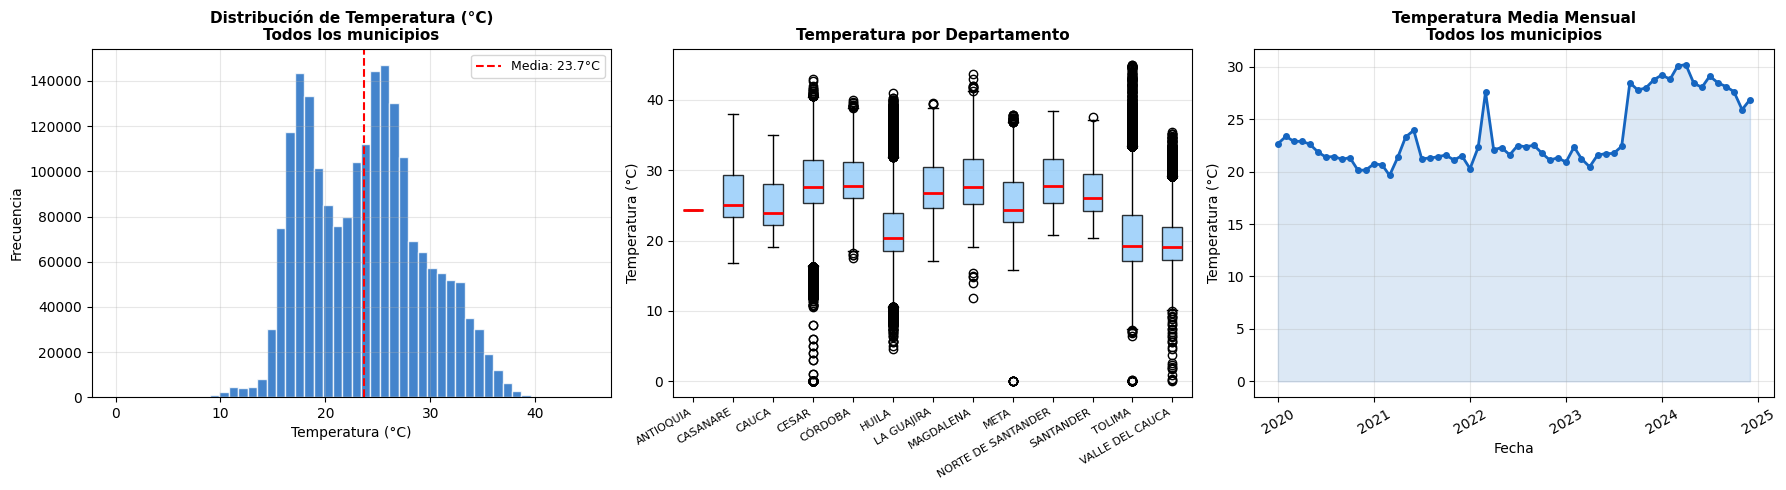

In [11]:
# ============================================================
# VISUALIZACIÓN — Temperatura por municipio y periodo
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── Gráfica 1: Histograma general de temperatura ─────────────
axes[0].hist(
    df_temp["valorobservado"].dropna(),
    bins=50, color="#1565C0", alpha=0.8, edgecolor="white"
)
axes[0].set_title("Distribución de Temperatura (°C)\nTodos los municipios",
                  fontsize=11, fontweight="bold")
axes[0].set_xlabel("Temperatura (°C)")
axes[0].set_ylabel("Frecuencia")
axes[0].axvline(df_temp["valorobservado"].mean(), color="red",
                linestyle="--", linewidth=1.5, label=f"Media: {df_temp['valorobservado'].mean():.1f}°C")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Gráfica 2: Boxplot por departamento ──────────────────────
deptos = df_temp["departamento"].unique()
datos_box = [df_temp[df_temp["departamento"]==d]["valorobservado"].dropna().values
             for d in deptos]
bp = axes[1].boxplot(datos_box, labels=deptos, patch_artist=True,
                     medianprops={"color": "red", "linewidth": 2})
for patch in bp["boxes"]:
    patch.set_facecolor("#90CAF9")
    patch.set_alpha(0.8)
axes[1].set_title("Temperatura por Departamento",
                  fontsize=11, fontweight="bold")
axes[1].set_ylabel("Temperatura (°C)")
axes[1].set_xticklabels(deptos, rotation=30, ha="right", fontsize=8)
axes[1].grid(True, alpha=0.3, axis="y")

# ── Gráfica 3: Temperatura media mensual (serie de tiempo) ───
df_serie = (
    df_temp.groupby(["Año", "Mes"])["valorobservado"]
    .mean()
    .reset_index()
)
df_serie["fecha"] = pd.to_datetime(
    df_serie["Año"].astype(str) + "-" + df_serie["Mes"].astype(str).str.zfill(2) + "-01"
)
df_serie = df_serie.sort_values("fecha")

axes[2].plot(df_serie["fecha"], df_serie["valorobservado"],
             color="#1565C0", linewidth=2, marker="o", markersize=4)
axes[2].fill_between(df_serie["fecha"], df_serie["valorobservado"],
                     alpha=0.15, color="#1565C0")
axes[2].set_title("Temperatura Media Mensual\nTodos los municipios",
                  fontsize=11, fontweight="bold")
axes[2].set_ylabel("Temperatura (°C)")
axes[2].set_xlabel("Fecha")
axes[2].tick_params(axis="x", rotation=30)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 💾 CELDA 12 — Guardar serie larga en `data/processed/`

In [14]:
# ============================================================
# GUARDAR SERIE LARGA CON CALENDARIO
# ⚠️  Con Top-50 municipios el DataFrame supera 1M filas.
#    → Formato principal: Parquet (sin límite de filas)
#    → Formato muestra:   Excel con las primeras 50,000 filas
# ============================================================

# Renombrar para nombre canónico del módulo
df_temperatura = df_temp.copy()

n_filas = df_temperatura.shape[0]
print(f'📊 Serie larga: {n_filas:,} filas × {df_temperatura.shape[1]} columnas')

# ── Guardado principal en Parquet (soporta >1M filas) ────
df_temperatura.to_parquet(ARCHIVO_LONG_PARQUET, index=False)
size_mb = os.path.getsize(ARCHIVO_LONG_PARQUET) / 1_048_576
print(f'✅ 15_DF_Temperatura_Long.parquet  → {ARCHIVO_LONG_PARQUET}')
print(f'   Shape  : {n_filas:,} × {df_temperatura.shape[1]}')
print(f'   Tamaño : {size_mb:.2f} MB')

# ── Muestra Excel (primeras 50K filas) ───────────────────
LIMITE_EXCEL = 50_000
df_muestra   = df_temperatura.head(LIMITE_EXCEL)
df_muestra.to_excel(ARCHIVO_LONG, index=False, engine='openpyxl')
print(f'✅ 15_DF_Temperatura_Long.xlsx  → muestra de {len(df_muestra):,} filas (de {n_filas:,})')
print(f'   ⚠️  Para análisis completo usa el archivo .parquet')

📊 Serie larga: 2,065,327 filas × 24 columnas
✅ 15_DF_Temperatura_Long.parquet  → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/15_DF_Temperatura_Long.parquet
   Shape  : 2,065,327 × 24
   Tamaño : 24.15 MB
✅ 15_DF_Temperatura_Long.xlsx  → muestra de 50,000 filas (de 2,065,327)
   ⚠️  Para análisis completo usa el archivo .parquet


---
## 📐 CELDA 13 — Agregación primaria: métricas diarias por municipio

Colapsa las múltiples lecturas del día (horarias o sub-horarias) en **una fila por día**,  
calculando temperatura media, mínima, máxima y desviación estándar.

In [15]:
# ============================================================
# AGREGACIÓN PRIMARIA — Métricas diarias por municipio
# Nivel: Periodo × Depto × Municipio × mes_periodo × Día
# ============================================================

print("🔢 Calculando métricas diarias (media, mínima, máxima, std)...")

# Asegurar tipo numérico
df_temperatura["valorobservado"] = pd.to_numeric(
    df_temperatura["valorobservado"], errors="coerce"
)

COLS_GRUPO_DIA = ["Periodo", "departamento", "municipio", "mes_periodo", "Dia"]

df_temperatura_agr = (
    df_temperatura
    .groupby(COLS_GRUPO_DIA, as_index=False)
    .agg(
        temperatura_media  = ("valorobservado", "mean"),
        temperatura_minima = ("valorobservado", "min"),
        temperatura_maxima = ("valorobservado", "max"),
        temperatura_std    = ("valorobservado", "std"),
        n_lecturas         = ("valorobservado", "count"),   # trazabilidad
    )
)

# Redondear a 3 decimales
COLS_TEMP = ["temperatura_media","temperatura_minima","temperatura_maxima","temperatura_std"]
df_temperatura_agr[COLS_TEMP] = df_temperatura_agr[COLS_TEMP].round(3)

reporte_df(df_temperatura_agr, "df_temperatura_agr — Agregación diaria")
display(df_temperatura_agr.head(8))

🔢 Calculando métricas diarias (media, mínima, máxima, std)...

  📊 df_temperatura_agr — Agregación diaria
  Filas    : 21,063
  Columnas : 10
  Nulos    : ⚠️  1 cols con nulos
             - temperatura_std: 87 (0.4%)



,Periodo,departamento,municipio,mes_periodo,Dia,temperatura_media,temperatura_minima,temperatura_maxima,temperatura_std,n_lecturas
0,2020A,CASANARE,PAZ DE ARIPORO,1,1,25.950,20.1,31.8,3.881,24
1,2020A,CASANARE,PAZ DE ARIPORO,1,2,25.683,20.6,31.8,4.140,24
2,2020A,CASANARE,PAZ DE ARIPORO,1,3,25.521,20.1,31.8,4.467,24
3,2020A,CASANARE,PAZ DE ARIPORO,1,4,25.438,19.2,32.3,4.759,24
4,2020A,CASANARE,PAZ DE ARIPORO,1,5,25.454,19.2,32.0,4.580,24
5,2020A,CASANARE,PAZ DE ARIPORO,1,6,25.238,18.6,32.0,4.863,24
6,2020A,CASANARE,PAZ DE ARIPORO,1,7,26.554,21.8,32.4,4.031,24
7,2020A,CASANARE,PAZ DE ARIPORO,1,8,26.275,21.7,32.0,3.931,24


---
## 💾 CELDA 14 — Guardar agregación diaria en `data/processed/`

In [16]:
# ============================================================
# GUARDAR AGREGACIÓN PRIMARIA
# ⚠️  La agregación diaria puede superar 1M filas con Top-50.
#    → Formato principal: Parquet
#    → Formato muestra:   Excel con las primeras 50,000 filas
# ============================================================

n_filas_agr = df_temperatura_agr.shape[0]
print(f'📊 Agregación diaria: {n_filas_agr:,} filas × {df_temperatura_agr.shape[1]} columnas')

# ── Guardado principal en Parquet ────────────────────────
df_temperatura_agr.to_parquet(ARCHIVO_AGR_PARQUET, index=False)
size_mb_agr = os.path.getsize(ARCHIVO_AGR_PARQUET) / 1_048_576
print(f'✅ 16_DF_Temperatura_Agr.parquet  → {ARCHIVO_AGR_PARQUET}')
print(f'   Shape  : {n_filas_agr:,} × {df_temperatura_agr.shape[1]}')
print(f'   Tamaño : {size_mb_agr:.2f} MB')

# ── Muestra Excel (primeras 50K filas) ───────────────────
LIMITE_EXCEL_AGR = 50_000
if n_filas_agr <= 1_048_576:
    df_temperatura_agr.to_excel(ARCHIVO_AGR, index=False, engine='openpyxl')
    print(f'✅ 16_DF_Temperatura_Agr.xlsx  → {n_filas_agr:,} filas (completo en Excel)')
else:
    df_temperatura_agr.head(LIMITE_EXCEL_AGR).to_excel(ARCHIVO_AGR, index=False, engine='openpyxl')
    print(f'✅ 16_DF_Temperatura_Agr.xlsx  → muestra {LIMITE_EXCEL_AGR:,} filas (de {n_filas_agr:,})')
    print(f'   ⚠️  Usa el .parquet para análisis completo')

📊 Agregación diaria: 21,063 filas × 10 columnas
✅ 16_DF_Temperatura_Agr.parquet  → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/16_DF_Temperatura_Agr.parquet
   Shape  : 21,063 × 10
   Tamaño : 0.24 MB
✅ 16_DF_Temperatura_Agr.xlsx  → 21,063 filas (completo en Excel)


---
## 📐 CELDA 15 — Agregación secundaria: métricas por mes del semestre

Colapsa los días dentro de cada mes semestral en **una fila por mes-semestre**,  
produciendo la granularidad necesaria para el pivoteo wide (columnas m1 a m6).

In [17]:
# ============================================================
# AGREGACIÓN SECUNDARIA — Métricas por mes del semestre
# Nivel: Periodo × Depto × Municipio × mes_periodo
# ============================================================

print("🔢 Calculando métricas por mes del semestre (sin dimensión Día)...")

COLS_GRUPO_MES = ["Periodo", "departamento", "municipio", "mes_periodo"]

df_temperatura_agr_sd = (
    df_temperatura_agr
    .groupby(COLS_GRUPO_MES, as_index=False)
    .agg(
        temperatura_media  = ("temperatura_media",  "mean"),
        temperatura_minima = ("temperatura_minima", "min"),
        temperatura_maxima = ("temperatura_maxima", "max"),
        temperatura_std    = ("temperatura_std",    "mean"),
        n_dias             = ("n_lecturas",         "count"),  # días con dato
    )
)

df_temperatura_agr_sd[COLS_TEMP] = df_temperatura_agr_sd[COLS_TEMP].round(3)

reporte_df(df_temperatura_agr_sd, "df_temperatura_agr_sd — Agregación por mes semestral")
display(df_temperatura_agr_sd.head(10))

# Verificar completitud de mes_periodo (deben existir m1..m6 para cada combo)
print("\n📊 Distribución de mes_periodo:")
print(df_temperatura_agr_sd["mes_periodo"].value_counts().sort_index().to_string())

🔢 Calculando métricas por mes del semestre (sin dimensión Día)...

  📊 df_temperatura_agr_sd — Agregación por mes semestral
  Filas    : 879
  Columnas : 9
  Nulos    : ⚠️  1 cols con nulos
             - temperatura_std: 5 (0.6%)



,Periodo,departamento,municipio,mes_periodo,temperatura_media,temperatura_minima,temperatura_maxima,temperatura_std,n_dias
0,2020A,CASANARE,PAZ DE ARIPORO,1,26.707,18.6,35.2,4.066,31
1,2020A,CASANARE,PAZ DE ARIPORO,2,27.892,19.2,36.1,4.512,26
2,2020A,CASANARE,PAZ DE ARIPORO,3,28.861,19.1,37.4,4.514,30
3,2020A,CASANARE,PAZ DE ARIPORO,4,27.449,21.7,38.0,3.675,30
4,2020A,CASANARE,PAZ DE ARIPORO,5,26.506,21.4,35.3,3.078,31
5,2020A,CASANARE,PAZ DE ARIPORO,6,25.817,21.6,33.8,2.746,30
6,2020A,CESAR,AGUACHICA,1,29.743,20.8,39.3,4.274,31
7,2020A,CESAR,AGUACHICA,2,31.769,23.5,41.6,4.409,29
8,2020A,CESAR,AGUACHICA,3,31.868,22.4,40.8,4.230,31
9,2020A,CESAR,AGUACHICA,4,30.092,23.5,40.1,3.771,30



📊 Distribución de mes_periodo:
mes_periodo
1    140
2    149
3    150
4    152
5    144
6    144


---
## 💾 CELDA 16 — Guardar agregación secundaria en `data/processed/`

In [18]:
# ============================================================
# GUARDAR AGREGACIÓN SECUNDARIA
# Destino: data/processed/17_DF_Temperatura_Agr_SD.xlsx
# ============================================================

guardar_excel(
    df_temperatura_agr_sd,
    ARCHIVO_AGR_SD,
    nombre_log="17_DF_Temperatura_Agr_SD.xlsx"
)

✅ 17_DF_Temperatura_Agr_SD.xlsx → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/17_DF_Temperatura_Agr_SD.xlsx
   Shape: 879 × 9



---
## 🔄 CELDA 17 — Pivoteo wide: temperatura por mes del semestre (m1 a m6)

Transforma el formato largo (una fila por mes semestral) al **formato wide**  
requerido para el join con EVA en MOD-05:

| Periodo | departamento | municipio | temp_media_m1 | ... | temp_std_m6 |
|---------|-------------|-----------|---------------|-----|-------------|

In [19]:
# ============================================================
# PIVOTEO WIDE — Una fila por (Periodo, Depto, Municipio)
# Columnas: temperatura_<metrica>_m<1..6>
# ============================================================

print("🔄 Pivoteando a formato wide...")

df_temperatura_wide = (
    df_temperatura_agr_sd
    .pivot_table(
        index   = ["Periodo", "departamento", "municipio"],
        columns = "mes_periodo",
        values  = COLS_TEMP,
        aggfunc = "first"    # ya está a nivel mes_periodo, no hay duplicados
    )
)

# ── Aplanar nombres de columna MultiIndex ────────────────────
df_temperatura_wide.columns = [
    f"{var}_m{mes}" for var, mes in df_temperatura_wide.columns
]
df_temperatura_wide = df_temperatura_wide.reset_index()

# ── Ordenar columnas: identificadores primero ────────────────
cols_id   = ["Periodo", "departamento", "municipio"]
cols_wide = sorted([c for c in df_temperatura_wide.columns if c not in cols_id])
df_temperatura_wide = df_temperatura_wide[cols_id + cols_wide]

reporte_df(df_temperatura_wide, "df_temperatura_wide — Formato wide (m1..m6)")

# Vista de columnas generadas
print("📋 Columnas generadas:")
for col in cols_wide:
    print(f"   {col}")

print()
display(df_temperatura_wide.head(5))

🔄 Pivoteando a formato wide...

  📊 df_temperatura_wide — Formato wide (m1..m6)
  Filas    : 193
  Columnas : 27
  Nulos    : ⚠️  24 cols con nulos
             - temperatura_maxima_m1: 53 (27.5%)
             - temperatura_maxima_m2: 44 (22.8%)
             - temperatura_maxima_m3: 43 (22.3%)
             - temperatura_maxima_m4: 41 (21.2%)
             - temperatura_maxima_m5: 49 (25.4%)
             - temperatura_maxima_m6: 49 (25.4%)
             - temperatura_media_m1: 53 (27.5%)
             - temperatura_media_m2: 44 (22.8%)
             - temperatura_media_m3: 43 (22.3%)
             - temperatura_media_m4: 41 (21.2%)
             - temperatura_media_m5: 49 (25.4%)
             - temperatura_media_m6: 49 (25.4%)
             - temperatura_minima_m1: 53 (27.5%)
             - temperatura_minima_m2: 44 (22.8%)
             - temperatura_minima_m3: 43 (22.3%)
             - temperatura_minima_m4: 41 (21.2%)
             - temperatura_minima_m5: 49 (25.4%)
             - temperatur

,Periodo,departamento,municipio,temperatura_maxima_m1,temperatura_maxima_m2,temperatura_maxima_m3,temperatura_maxima_m4,temperatura_maxima_m5,temperatura_maxima_m6,temperatura_media_m1,...,temperatura_minima_m3,temperatura_minima_m4,temperatura_minima_m5,temperatura_minima_m6,temperatura_std_m1,temperatura_std_m2,temperatura_std_m3,temperatura_std_m4,temperatura_std_m5,temperatura_std_m6
0,2020A,CASANARE,PAZ DE ARIPORO,35.2,36.1,37.4,38.0,35.3,33.8,26.707,...,19.1,21.7,21.4,21.6,4.066,4.512,4.514,3.675,3.078,2.746
1,2020A,CESAR,AGUACHICA,39.3,41.6,40.8,40.1,38.7,36.9,29.743,...,22.4,23.5,23.5,21.9,4.274,4.409,4.230,3.771,3.324,3.289
2,2020A,CESAR,CURUMANÍ,39.2,41.0,40.3,39.9,40.2,36.0,27.894,...,19.9,23.1,23.1,22.9,4.655,5.035,4.977,3.987,3.423,3.048
3,2020A,CESAR,EL PASO,40.2,42.6,40.8,39.9,40.4,39.0,30.184,...,23.7,24.4,23.6,21.8,4.175,4.491,4.218,3.830,3.292,3.185
4,2020A,CESAR,PAILITAS,40.9,37.1,38.4,38.4,39.1,37.0,32.971,...,21.7,22.9,22.8,22.2,2.369,3.432,4.212,3.684,3.340,3.340


---
## 📊 CELDA 18 — Visualización del formato wide: heatmap de cobertura

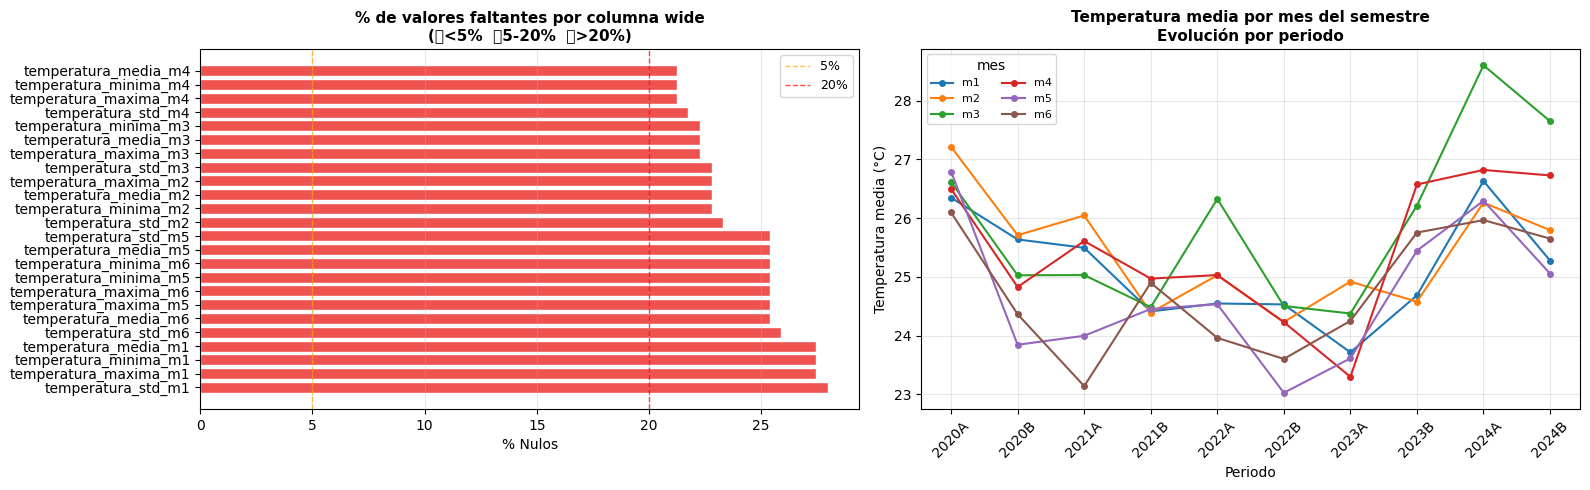

In [20]:
# ============================================================
# VISUALIZACIÓN — Cobertura del formato wide por municipio-periodo
# ============================================================

# ── Mapa de calor: % de nulos por columna wide ───────────────
cols_temp_wide = [c for c in df_temperatura_wide.columns
                  if c.startswith("temperatura_")]

pct_nulos = (
    df_temperatura_wide[cols_temp_wide]
    .isna()
    .mean()
    .rename("pct_nulo")
    .mul(100)
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Barras de % nulos
colores_nulo = ["#EF5350" if v > 20 else "#FFA726" if v > 5 else "#66BB6A"
                for v in pct_nulos.values]
axes[0].barh(pct_nulos.index, pct_nulos.values,
             color=colores_nulo, edgecolor="white")
axes[0].axvline(5,  color="orange", linestyle="--", linewidth=1, alpha=0.7, label="5%")
axes[0].axvline(20, color="red",    linestyle="--", linewidth=1, alpha=0.7, label="20%")
axes[0].set_title("% de valores faltantes por columna wide\n(🟢<5%  🟠5-20%  🔴>20%)",
                  fontsize=11, fontweight="bold")
axes[0].set_xlabel("% Nulos")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3, axis="x")

# Temperatura media m1..m6 por periodo (media de todos los municipios)
cols_media = sorted([c for c in cols_temp_wide if "temperatura_media_" in c])
if cols_media:
    df_evo = df_temperatura_wide.groupby("Periodo")[cols_media].mean().reset_index()
    df_evo_sorted = df_evo.sort_values("Periodo")

    for col in cols_media:
        mes_lbl = col.replace("temperatura_media_", "")
        axes[1].plot(
            df_evo_sorted["Periodo"],
            df_evo_sorted[col],
            marker="o", linewidth=1.5, markersize=4, label=mes_lbl
        )

    axes[1].set_title("Temperatura media por mes del semestre\nEvolución por periodo",
                      fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Periodo")
    axes[1].set_ylabel("Temperatura media (°C)")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend(title="mes", fontsize=8, ncol=2)
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 💾 CELDA 19 — Guardar formato wide en `data/processed/`

In [21]:
# ============================================================
# GUARDAR FORMATO WIDE
# Destino: data/processed/18_DF_Temperatura_Wide.xlsx
# ============================================================

guardar_excel(
    df_temperatura_wide,
    ARCHIVO_WIDE,
    nombre_log="18_DF_Temperatura_Wide.xlsx"
)

✅ 18_DF_Temperatura_Wide.xlsx → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/18_DF_Temperatura_Wide.xlsx
   Shape: 193 × 27



---
## ✅ CELDA 20 — Resumen de ejecución del módulo

In [22]:
# ============================================================
# RESUMEN FINAL — MOD-03 completado
# ============================================================

print("=" * 62)
print("  ✅ MOD-03 — Temperatura IDEAM  COMPLETADO")
print("=" * 62)

print("\n📦 Archivos generados:")
salidas = [
    ("data/raw/",       "03_raw_Temperatura.parquet",
     "Descarga original comprimida (sin modificar)"),
    ("data/processed/", "15_DF_Temperatura_Long.parquet",
     f"Serie larga completa (Parquet)  — {df_temperatura.shape[0]:,} registros"),
    ("data/processed/", "15_DF_Temperatura_Long.xlsx",
     f"Muestra Excel (primeras 50K filas, para inspección)"),
    ("data/processed/", "16_DF_Temperatura_Agr.parquet",
     f"Métricas diarias (Parquet)  — {df_temperatura_agr.shape[0]:,} filas"),
    ("data/processed/", "16_DF_Temperatura_Agr.xlsx",
     f"Muestra Excel (hasta 50K filas)"),
    ("data/processed/", "17_DF_Temperatura_Agr_SD.xlsx",
     f"Métricas por mes semestral  — {df_temperatura_agr_sd.shape[0]:,} filas"),
    ("data/processed/", "18_DF_Temperatura_Wide.xlsx",
     f"Formato wide m1..m6         — {df_temperatura_wide.shape[0]:,} filas × {df_temperatura_wide.shape[1]} cols"),
]
for carpeta, archivo, desc in salidas:
    print(f"   📄 {carpeta}{archivo}")
    print(f"      {desc}")

print("\n📊 DataFrames disponibles para módulos siguientes:")
print(f"   df_temperatura       → serie larga (long)")
print(f"   df_temperatura_agr   → métricas diarias")
print(f"   df_temperatura_agr_sd→ métricas por mes semestral")
print(f"   df_temperatura_wide  → formato wide — LISTO para MOD-05")

print("\n🗺️  Cobertura de datos:")
print(f"   Periodos cubiertos: {sorted(df_temperatura_wide['Periodo'].unique())}")
print(f"   Municipios con wide: {df_temperatura_wide[['departamento','municipio']].drop_duplicates().shape[0]}")
n_nulos_wide = df_temperatura_wide[cols_temp_wide].isna().sum().sum()
total_celdas  = df_temperatura_wide.shape[0] * len(cols_temp_wide)
print(f"   Completitud wide: {(1-n_nulos_wide/total_celdas)*100:.1f}% (nulos = {n_nulos_wide:,}/{total_celdas:,})")
print(f"   Nota: Los nulos serán imputados en MOD-06.")

print("\n➡️  Siguiente módulo : MOD-05 — Precipitación y Radiación Solar")
print("    Entrada esperada  : filtros (misma lista depto-municipio)")
print("    API destino       : datos.gov.co recurso s54a-sgyg (Precipitación)")
print("=" * 62)

  ✅ MOD-03 — Temperatura IDEAM  COMPLETADO

📦 Archivos generados:
   📄 data/raw/03_raw_Temperatura.parquet
      Descarga original comprimida (sin modificar)
   📄 data/processed/15_DF_Temperatura_Long.parquet
      Serie larga completa (Parquet)  — 2,065,327 registros
   📄 data/processed/15_DF_Temperatura_Long.xlsx
      Muestra Excel (primeras 50K filas, para inspección)
   📄 data/processed/16_DF_Temperatura_Agr.parquet
      Métricas diarias (Parquet)  — 21,063 filas
   📄 data/processed/16_DF_Temperatura_Agr.xlsx
      Muestra Excel (hasta 50K filas)
   📄 data/processed/17_DF_Temperatura_Agr_SD.xlsx
      Métricas por mes semestral  — 879 filas
   📄 data/processed/18_DF_Temperatura_Wide.xlsx
      Formato wide m1..m6         — 193 filas × 27 cols

📊 DataFrames disponibles para módulos siguientes:
   df_temperatura       → serie larga (long)
   df_temperatura_agr   → métricas diarias
   df_temperatura_agr_sd→ métricas por mes semestral
   df_temperatura_wide  → formato wide — LISTO pa